# Steepest descent — implementazione e verifiche

Nel punto 2 dell'Esercizio 1 (PART 1 + 2) ogni simulazione parte da un **minimo locale** dell'energia
potenziale, trovato con la *steepest descent*. Il testo fissa
$C=0.005$ Å²/eV e chiede di fermarsi quando $\max_k|\mathbf F(k)|<10^{-3}$ eV/Å.
La teoria è nel capitolo [Steepest descent: teoria](../../book/teoria/06_steepest_descent.md);
qui si implementa l'algoritmo, lo si verifica e si rispondono con i numeri alle
domande lasciate aperte.

| Sezione | Domanda |
|---|---|
| §1–2 | L'algoritmo della slide funziona? Riproduce l'esempio da 864 atomi? |
| §3 | Cosa succede al cluster dell'esercizio: chi si sposta, e di quanto? Ruota o trasla? |
| §4 | Come si sceglie $C$, e cosa succede se è troppo grande? |
| §5 | $F_\text{tol}=10^{-3}$ o $10^{-5}$ eV/Å: quanto conta? |
| §6 | Che effetto ha la minimizzazione sulla MD? |

In [1]:
import sys
from pathlib import Path


def _setup_path():
    root = Path.cwd()
    for _ in range(10):
        if (root / "pyproject.toml").exists():
            break
        root = root.parent
    for sub in ("src", "materials"):
        path = str(root / sub)
        if path not in sys.path:
            sys.path.insert(0, path)
    return root


ROOT = _setup_path()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from poly7 import poly7  # file del corso: materials/poly7.py

from computational_course.fcc_lattice import fcc_supercell
from computational_course.md import KB_EV, assign_vel
from computational_course.md_p7 import (
    lj_p7_model,
    max_force,
    production_stats,
    run_nve,
    steepest_descent,
)

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.size": 10,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.axisbelow": True,
    }
)

EPSILON, SIGMA, RC, RP = 0.345, 2.644, 4.5, 4.2  # eV, Å, Å, Å
C_STEEP = 0.005  # Å²/eV, coefficiente del testo
F_TOL = 1e-3  # eV/Å, soglia del testo
MASS = 108.0 * 1.66e-27 / 16.0  # massa Ag in unità di codice (eV s²/Å²)
FS = 1e-15  # s
A_AG = 4.1604  # Å, passo reticolare dei file del corso

lp = poly7(EPSILON, SIGMA, RC, RP)
P7 = np.array([lp.A, lp.B, lp.C, lp.D, lp.E, lp.F, lp.G, lp.H])
modello = lj_p7_model(SIGMA, EPSILON, RC, rp=RP, p7=P7)  # LJ + P7, nessuna PBC

FILE_256 = ROOT / "data" / "raw" / "fcc100a256.txt"
pos0 = np.loadtxt(FILE_256) if FILE_256.exists() else fcc_supercell(A_AG, 4, 4, 4)[0]
natoms = len(pos0)

SERIE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # ordine fisso delle serie
GRIGIO = "#52514e"

## 1. L'algoritmo

La slide 38 descrive l'algoritmo in quattro righe: si calcolano le forze, si
controlla la forza massima e, se non è ancora sotto soglia, si sposta ogni
atomo lungo la propria forza. La funzione `steepest_descent` di
`computational_course.md_p7` fa esattamente questo:

```python
for _ in range(max_iter):
    fmax = max_force(force)            # max_k |F(k)|
    if fmax < ftol:
        break                          # convergenza raggiunta
    pos = pos + c * force              # δr(k) = C·F(k)
    epot, force, _ = energy_forces(pos)
```

Le forze arrivano dalla **stessa funzione usata nella MD**, `energy_forces`
(LJ con il raccordo $P_7$). Non servono liste dei vicini: il ciclo scorre
tutte le $N(N-1)/2$ coppie e scarta quelle oltre $r_c$, che per $N=256$ è
abbastanza veloce. La funzione registra anche $E$ e $F_\text{max}$ a ogni
iterazione, per i due controlli della slide: l'energia deve **sempre**
scendere, mentre la forza massima può crescere ogni tanto.

## 2. Verifica: l'esempio delle slide (cluster di 864 atomi)

La slide 39 mostra $E$ e $F_\text{max}$ in funzione delle iterazioni per un
cluster di Ag di 864 atomi, con $C=0.003$ e $C=0.01$ Å²/eV. Il file
`fcc100a864.txt` è già in `data/raw/`, quindi si può ripetere la prova.

,E iniziale [eV],E finale [eV],F_max iniziale [eV/Å],iterazioni,E sempre decrescente,aumenti di F_max
C [Å²/eV],,,,,,
0.003,-1681.8627,-1682.3885,0.197,1802,sì,13
0.01,-1681.8627,-1682.3885,0.197,540,sì,4


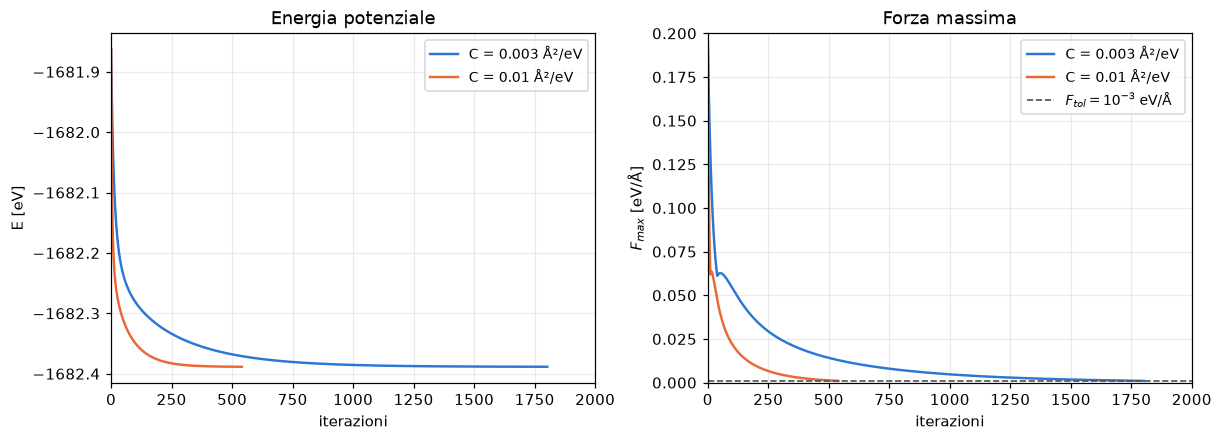

In [2]:
pos864 = np.loadtxt(ROOT / "data" / "raw" / "fcc100a864.txt")
sd864 = {c: steepest_descent(pos864, modello, c=c, ftol=F_TOL) for c in (0.003, 0.01)}

righe = []
for c, sd in sd864.items():
    righe.append(
        {
            "C [Å²/eV]": c,
            "E iniziale [eV]": sd["energy"][0],
            "E finale [eV]": sd["energy"][-1],
            "F_max iniziale [eV/Å]": sd["fmax"][0],
            "iterazioni": sd["n_iter"],
            "E sempre decrescente": "sì" if np.all(np.diff(sd["energy"]) <= 0) else "no",
            "aumenti di F_max": int(np.count_nonzero(np.diff(sd["fmax"]) > 0)),
        }
    )
display(
    pd.DataFrame(righe)
    .set_index("C [Å²/eV]")
    .style.format({"E iniziale [eV]": "{:.4f}", "E finale [eV]": "{:.4f}", "F_max iniziale [eV/Å]": "{:.3f}"})
    .format_index("{:g}")
    .set_caption("Cluster di 864 atomi, LJ + P7, F_tol = 1e-3 eV/Å")
)

fig, (ax_e, ax_f) = plt.subplots(1, 2, figsize=(11, 3.9), constrained_layout=True)
for colore, (c, sd) in zip(SERIE, sd864.items()):
    ax_e.plot(sd["energy"], color=colore, lw=1.6, label=f"C = {c:g} Å²/eV")
    ax_f.plot(sd["fmax"], color=colore, lw=1.6, label=f"C = {c:g} Å²/eV")
ax_f.axhline(F_TOL, color=GRIGIO, ls="--", lw=1.1, label=r"$F_{tol}=10^{-3}$ eV/Å")
ax_e.set(xlabel="iterazioni", ylabel="E [eV]", title="Energia potenziale", xlim=(0, 2000))
ax_f.set(xlabel="iterazioni", ylabel=r"$F_{max}$ [eV/Å]", title="Forza massima", xlim=(0, 2000), ylim=(0, 0.2))
ax_e.legend(fontsize=9)
ax_f.legend(fontsize=9)
plt.show()

**Lettura.** Con il modello dell'esercizio il risultato coincide con la slide
39:

- $E$ passa da $-1681.86$ a $-1682.39$ eV e $F_\text{max}$ parte da circa
  $0.2$ eV/Å;
- con $C=0.01$ si converge circa 3 volte prima che con $C=0.003$ (540 contro
  1802 iterazioni), cioè in proporzione a $C$;
- i due controlli della slide («Is it working?») sono superati: l'energia
  scende a **ogni** iterazione, mentre $F_\text{max}$ cresce qualche volta
  (13 e 4 volte), come nella slide.

Gli aumenti di $F_\text{max}$ non sono un errore. L'algoritmo minimizza
l'energia, che è una somma su tutti gli atomi; $F_\text{max}$ guarda solo
l'atomo peggiore, e questo può peggiorare per un passo mentre il resto del
cluster migliora.

## 3. Il cluster dell'esercizio (256 atomi)

Si applica ora la ricetta del testo, $C=0.005$ Å²/eV e
$F_\text{tol}=10^{-3}$ eV/Å, alla cella dell'esercizio. Per capire **chi** si
sposta, gli atomi vengono divisi in base al numero di primi vicini
(coordinazione) nel reticolo ideale:

- 12 per gli atomi interni;
- 8 per quelli sulle facce;
- 5 per quelli sugli spigoli;
- 3 per i vertici del cubo.

Di ogni spostamento interessa anche la **componente radiale**: positiva se
l'atomo si allontana dal centro del cluster, negativa se si avvicina.

In [3]:
sd = steepest_descent(pos0, modello, c=C_STEEP, ftol=F_TOL)
pos_min = sd["pos"]
print(
    f"convergenza: {sd['converged']} in {sd['n_iter']} iterazioni; "
    f"E: {sd['energy'][0]:.4f} -> {sd['energy'][-1]:.4f} eV "
    f"(ΔE = {sd['energy'][-1] - sd['energy'][0]:.4f} eV); "
    f"F_max: {sd['fmax'][0]:.3f} -> {sd['fmax'][-1]:.1e} eV/Å"
)

dist0 = np.linalg.norm(pos0[:, None] - pos0[None], axis=-1)
coord = np.count_nonzero((dist0 > 0.1) & (dist0 < 0.5 * (A_AG / np.sqrt(2) + A_AG)), axis=1)
centro = pos0.mean(axis=0)
spost = pos_min - pos0
radiale = np.einsum("ij,ij->i", spost, pos0 - centro) / np.linalg.norm(pos0 - centro, axis=1)
nomi = {12: "interno", 8: "faccia", 5: "spigolo", 3: "vertice"}
gruppi = pd.DataFrame(
    [
        {
            "atomi": nomi.get(z, str(z)),
            "coordinazione": z,
            "quanti": int(np.count_nonzero(coord == z)),
            "|δr| medio [Å]": np.linalg.norm(spost[coord == z], axis=1).mean(),
            "|δr| max [Å]": np.linalg.norm(spost[coord == z], axis=1).max(),
            "δr radiale medio [Å]": radiale[coord == z].mean(),
        }
        for z in sorted(set(coord), reverse=True)
    ]
).set_index("atomi")
display(gruppi.style.format("{:.4f}", subset=["|δr| medio [Å]", "|δr| max [Å]", "δr radiale medio [Å]"])
        .set_caption("Spostamenti dalla configurazione ideale al minimo"))

# traslazioni e rotazioni rigide
d_cm = np.linalg.norm(pos_min.mean(axis=0) - pos0.mean(axis=0))
rot = np.linalg.norm(np.cross(pos0 - centro, spost).sum(axis=0))
print(f"spostamento del centro di massa: {d_cm:.1e} Å")
print(f"|Σ_k (r_k - r_cm) × δr_k|: {rot:.1e} Å²  (zero = nessuna rotazione rigida)")

convergenza: True in 598 iterazioni; E: -453.4502 -> -453.6714 eV (ΔE = -0.2212 eV); F_max: 0.197 -> 1.0e-03 eV/Å


,coordinazione,quanti,|δr| medio [Å],|δr| max [Å],δr radiale medio [Å]
atomi,,,,,
interno,12,108,0.0168,0.0391,-0.0162
faccia,8,108,0.0231,0.0411,-0.0040
spigolo,5,36,0.0171,0.0355,-0.0148
vertice,3,4,0.0501,0.0501,-0.0501


spostamento del centro di massa: 1.3e-14 Å
|Σ_k (r_k - r_cm) × δr_k|: 5.5e-13 Å²  (zero = nessuna rotazione rigida)


**Lettura.**

- Servono 598 iterazioni, per $\Delta E=-0.22$ eV in tutto, meno di 1 meV per
  atomo. Come nella slide 39, le coordinate cambiano «molto poco»: lo
  spostamento massimo è $0.05$ Å, meno del 2% della distanza tra primi
  vicini.
- Tutti i gruppi hanno componente radiale negativa, quindi il cluster si
  **contrae**: gli atomi di superficie hanno meno vicini e si avvicinano a
  quelli che restano. Si spostano di più i vertici, con soli 3 primi vicini:
  $0.05$ Å, tutti verso il centro.
- Il cubo ha 8 vertici, ma con questa costruzione (la stessa dei file del
  corso) solo **4** sono occupati da un atomo. Ne va tenuto conto nel punto
  3, che chiede le traiettorie degli atomi ai vertici.
- Il centro di massa non si sposta e il cluster non ruota: entrambi i valori
  sono zero a meno degli arrotondamenti. Non è un caso. Con forze di coppia
  centrali la forza totale e il momento totale sono nulli, quindi lo
  spostamento $C\mathbf F(k)$ non contiene né traslazioni né rotazioni rigide.
  È la risposta alla domanda «e alle rotazioni?» (vedi la
  [teoria](../../book/teoria/06_steepest_descent.md)).

## 4. Come scegliere $C$

### 4.1 $C$ costante: quante iterazioni?

,iterazioni n,n · C [Å²/eV],E finale - E_min [eV]
C [Å²/eV],,,
0.001,2999,3.00,1.6e-05
0.002,1499,3.00,1.6e-05
0.003,998,2.99,1.6e-05
0.005,598,2.99,1.6e-05
0.01,298,2.98,1.6e-05
0.02,148,2.96,1.6e-05
0.05,58,2.90,1.6e-05


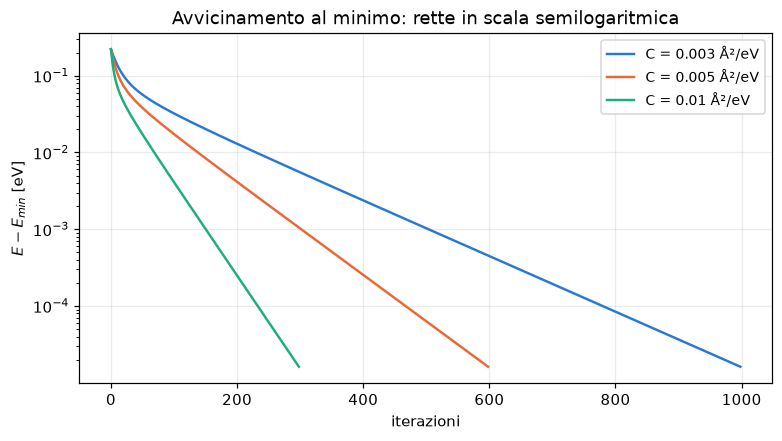

In [4]:
C_LISTA = [0.001, 0.002, 0.003, 0.005, 0.01, 0.02, 0.05]
prove_c = {c: steepest_descent(pos0, modello, c=c, ftol=F_TOL, max_iter=50_000) for c in C_LISTA}
riferimento = steepest_descent(pos0, modello, c=C_STEEP, ftol=1e-7, max_iter=50_000)
pos_rif, e_rif = riferimento["pos"], riferimento["energy"][-1]  # minimo "esatto" (F_tol = 1e-7)
display(
    pd.DataFrame(
        {
            "iterazioni n": [p["n_iter"] for p in prove_c.values()],
            "n · C [Å²/eV]": [p["n_iter"] * c for c, p in prove_c.items()],
            "E finale - E_min [eV]": [p["energy"][-1] - e_rif for p in prove_c.values()],
        },
        index=pd.Index(C_LISTA, name="C [Å²/eV]"),
    )
    .style.format({"n · C [Å²/eV]": "{:.2f}", "E finale - E_min [eV]": "{:.1e}"})
    .format_index("{:g}")
    .set_caption("Cluster di 256 atomi, F_tol = 1e-3 eV/Å; E_min: minimo con F_tol = 1e-7")
)

fig, ax = plt.subplots(figsize=(7, 3.9), constrained_layout=True)
for colore, c in zip(SERIE, (0.003, 0.005, 0.01)):
    ax.semilogy(prove_c[c]["energy"] - e_rif, color=colore, lw=1.6, label=f"C = {c:g} Å²/eV")
ax.set(xlabel="iterazioni", ylabel=r"$E - E_{min}$ [eV]",
       title="Avvicinamento al minimo: rette in scala semilogaritmica")
ax.legend(fontsize=9)
plt.show()

**Lettura.** Il numero di iterazioni è inversamente proporzionale a $C$:
$n\cdot C\approx3$ Å²/eV per tutti i valori provati. Nel grafico
$E-E_\text{min}$ scende lungo una retta in scala semilogaritmica. La
convergenza è quindi **lineare** (geometrica): a ogni passo l'errore si
moltiplica per lo stesso fattore, e raddoppiare $C$ raddoppia la pendenza.
Finora un $C$ più grande sembra solo un vantaggio; il limite arriva con il
§4.2.

### 4.2 Il limite di stabilità: $C<2/\lambda_\text{max}$

Vicino al minimo l'energia è quadratica e la sua curvatura è descritta
dall'**Hessiana** $H$, la matrice $3N\times3N$ delle derivate seconde. Per
ogni modo normale di curvatura $\lambda$, un passo moltiplica lo scostamento
dal minimo per $(1-C\lambda)$ (derivazione nella
[teoria](../../book/teoria/06_steepest_descent.md)). Si converge solo
se $|1-C\lambda|<1$ per **tutti** i modi, cioè $C<2/\lambda_\text{max}$.

$H$ si calcola nel minimo con le differenze finite delle forze: si sposta una
coordinata alla volta di $\pm h$ e si guarda come cambiano tutte le forze.

autovalori nulli (|λ| < 1e-5): 6  -> 3 traslazioni + 3 rotazioni
λ_min = 0.120 eV/Å²,  λ_max = 25.80 eV/Å²,  κ = λ_max/λ_min = 215
C_crit = 2/λ_max = 0.0775 Å²/eV;  C del testo = 0.005 -> C·λ_max = 0.13
modi con peso > 1e-6 nello spostamento ideale -> minimo: 40 su 768; il più morbido ha λ = 1.39 eV/Å²
frequenza massima di vibrazione: ν_max = 7.6 THz (periodo 131 fs)


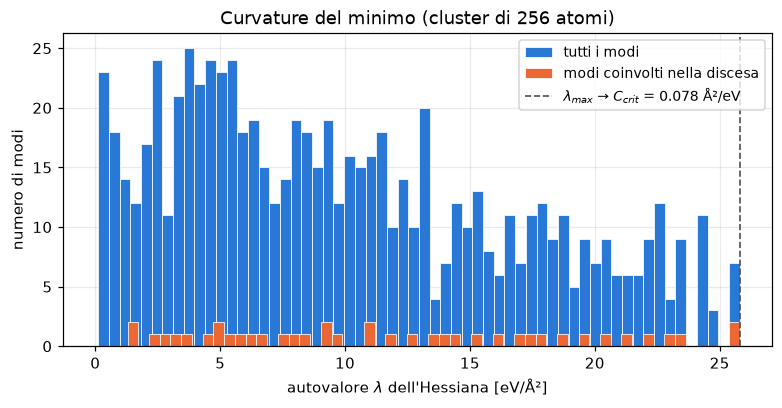

In [5]:
def hessiana(pos, h=1e-4):
    # H[a, b] = -dF_a/dx_b con differenze centrate, simmetrizzata
    n3 = pos.size
    hess = np.empty((n3, n3))
    for b in range(n3):
        piu, meno = pos.copy(), pos.copy()
        piu.flat[b] += h
        meno.flat[b] -= h
        hess[:, b] = -(modello(piu)[1].ravel() - modello(meno)[1].ravel()) / (2 * h)
    return 0.5 * (hess + hess.T)


lam, modi = np.linalg.eigh(hessiana(pos_rif))
nulli = int(np.count_nonzero(np.abs(lam) < 1e-5))
lam_min, lam_max = lam[nulli], lam[-1]
C_CRIT = 2.0 / lam_max
print(f"autovalori nulli (|λ| < 1e-5): {nulli}  -> 3 traslazioni + 3 rotazioni")
print(f"λ_min = {lam_min:.3f} eV/Å²,  λ_max = {lam_max:.2f} eV/Å²,  κ = λ_max/λ_min = {lam_max / lam_min:.0f}")
print(f"C_crit = 2/λ_max = {C_CRIT:.4f} Å²/eV;  C del testo = {C_STEEP} -> C·λ_max = {C_STEEP * lam_max:.2f}")

# quali modi partecipano davvero alla discesa dal reticolo ideale?
peso = (modi.T @ (pos0 - pos_rif).ravel()) ** 2
peso /= peso.sum()
attivi = peso > 1e-6
print(f"modi con peso > 1e-6 nello spostamento ideale -> minimo: {np.count_nonzero(attivi)} su {lam.size}; "
      f"il più morbido ha λ = {lam[attivi].min():.2f} eV/Å²")

# la stessa curvatura fissa la frequenza di vibrazione più alta
nu_max = np.sqrt(lam_max / MASS) / (2 * np.pi)
print(f"frequenza massima di vibrazione: ν_max = {nu_max / 1e12:.1f} THz (periodo {1e15 / nu_max:.0f} fs)")

fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
ax.hist(lam[nulli:], bins=60, color=SERIE[0], edgecolor="white", linewidth=0.5, label="tutti i modi")
ax.hist(lam[attivi], bins=60, range=(0, lam_max), color=SERIE[1], edgecolor="white", linewidth=0.5,
        label="modi coinvolti nella discesa")
ax.axvline(lam_max, color=GRIGIO, ls="--", lw=1.1, label=rf"$\lambda_{{max}}$ → $C_{{crit}}$ = {C_CRIT:.3f} Å²/eV")
ax.set(xlabel=r"autovalore $\lambda$ dell'Hessiana [eV/Å²]", ylabel="numero di modi",
       title="Curvature del minimo (cluster di 256 atomi)")
ax.legend(fontsize=9)
plt.show()

**Lettura.**

- I 6 autovalori nulli sono le 3 traslazioni e le 3 rotazioni rigide, che
  spostano il cluster senza cambiarne l'energia.
- Il limite è $C_\text{crit}=2/\lambda_\text{max}\approx0.078$ Å²/eV. Il
  $C=0.005$ del testo ne è circa 1/15: è sicuro, ma non il più veloce.
- **Perché $n\cdot C\approx3$.** Partendo dal reticolo ideale si muovono solo
  40 modi su 768; gli altri hanno peso nullo nello spostamento. È un effetto
  della simmetria della configurazione di partenza, che la discesa conserva.
  Il più morbido dei modi coinvolti ha $\lambda\approx1.39$ eV/Å², e su questo
  modo lo scostamento si riduce di $(1-C\lambda)\approx e^{-C\lambda}$ a ogni
  passo. Per portare $F_\text{max}$ da $0.2$ a $10^{-3}$ eV/Å servono quindi
  circa $\ln(200)/(C\lambda)\approx3.8/C$ iterazioni, lo stesso ordine del
  $3/C$ misurato. Il modo più morbido in assoluto ($\lambda_\text{min}=0.12$
  eV/Å²) non viene eccitato; se lo fosse, servirebbero circa 10 volte più
  iterazioni.
- **Il legame con la MD.** La curvatura più grande fissa anche la frequenza
  di vibrazione più alta del cluster, $7.6$ THz, cioè un periodo di 131 fs.
  I passi ottimali del punto 1 (2–20 fs) ne sono una piccola frazione.

### 4.3 Cosa succede oltre il limite

C = 0.90·C_crit = 0.0698: 'convergenza' = True in 41 iterazioni, E finale = -453.67 eV, energia sempre decrescente: True, atomi senza vicini entro r_c: 0
C = 1.05·C_crit = 0.0814: 'convergenza' = True in 160 iterazioni, E finale = -274.77 eV, energia sempre decrescente: False, atomi senza vicini entro r_c: 56


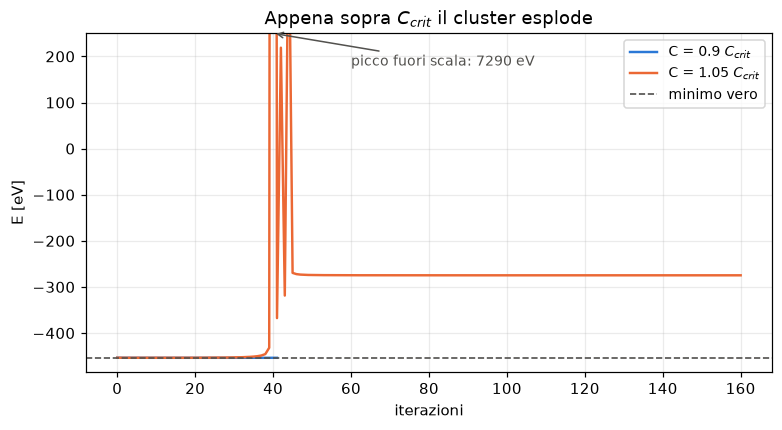

In [6]:
oltre = {}
for fattore in (0.9, 1.05):
    c = fattore * C_CRIT
    oltre[fattore] = steepest_descent(pos0, modello, c=c, ftol=F_TOL, max_iter=5000)
    r = oltre[fattore]
    d_fin = np.linalg.norm(r["pos"][:, None] - r["pos"][None], axis=-1)
    isolati = int(np.count_nonzero(((d_fin > 0) & (d_fin < RC)).sum(axis=1) == 0))
    print(
        f"C = {fattore:.2f}·C_crit = {c:.4f}: 'convergenza' = {r['converged']} in {r['n_iter']} iterazioni, "
        f"E finale = {r['energy'][-1]:.2f} eV, energia sempre decrescente: "
        f"{bool(np.all(np.diff(r['energy']) <= 0))}, atomi senza vicini entro r_c: {isolati}"
    )

fig, ax = plt.subplots(figsize=(7, 3.8), constrained_layout=True)
for colore, (fattore, r) in zip(SERIE, oltre.items()):
    ax.plot(r["energy"], color=colore, lw=1.6, label=f"C = {fattore:g} $C_{{crit}}$")
ax.axhline(e_rif, color=GRIGIO, ls="--", lw=1.1, label="minimo vero")
picco = oltre[1.05]["energy"].max()
ax.set_ylim(e_rif - 30, 250)
ax.annotate(f"picco fuori scala: {picco:.0f} eV", xy=(np.argmax(oltre[1.05]["energy"]), 250),
            xytext=(60, 180), fontsize=9, color=GRIGIO, arrowprops={"arrowstyle": "->", "color": GRIGIO})
ax.set(xlabel="iterazioni", ylabel="E [eV]", title="Appena sopra $C_{crit}$ il cluster esplode")
ax.legend(fontsize=9)
plt.show()

**Lettura.** Con $C=0.9\,C_\text{crit}$ si arriva allo stesso minimo in 41
iterazioni. Con $C=1.05\,C_\text{crit}$ i modi più rigidi crescono di un
fattore $|1-C\lambda|>1$ a ogni passo e il cluster **esplode**: l'energia
sale fino a circa $-275$ eV (il minimo è a $-453.67$ eV) e 56 atomi restano
senza vicini entro $r_c$.

Eppure il criterio su $F_\text{max}$ risulta soddisfatto, perché atomi
lontani tra loro non sentono forze. Per questo il primo controllo della slide,
«l'energia scende sempre?», è indispensabile: $F_\text{max}<F_\text{tol}$ da
solo non garantisce di essere in un minimo sensato.

### 4.4 $C$ adattivo

Con l'opzione `adaptive=True` un passo che fa **salire** l'energia viene
rifiutato e $C$ si dimezza, mentre un passo accettato moltiplica $C$ per 1.1.
Così l'energia scende sempre, anche partendo da un $C$ troppo grande.

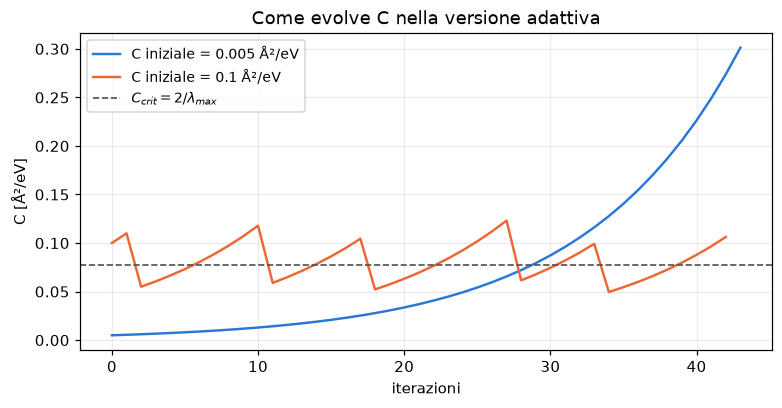

In [7]:
righe = []
storie = {}
for c0, adatt in ((C_STEEP, False), (C_STEEP, True), (0.1, True)):
    r = steepest_descent(pos0, modello, c=c0, ftol=F_TOL, adaptive=adatt)
    storie[c0, adatt] = r
    righe.append(
        {
            "C iniziale [Å²/eV]": c0,
            "adattivo": "sì" if adatt else "no",
            "iterazioni": r["n_iter"],
            "E finale - E_min [eV]": r["energy"][-1] - e_rif,
            "passi rifiutati": int(np.count_nonzero(np.diff(r["c"]) < 0)),
            "C massimo [Å²/eV]": r["c"].max(),
            "E sempre decrescente": "sì" if np.all(np.diff(r["energy"]) <= 0) else "no",
        }
    )
display(
    pd.DataFrame(righe)
    .set_index(["C iniziale [Å²/eV]", "adattivo"])
    .style.format({"E finale - E_min [eV]": "{:.1e}", "C massimo [Å²/eV]": "{:.4f}"})
    .format_index("{:g}", level=0)
    .set_caption(f"C adattivo (C_crit = {C_CRIT:.4f} Å²/eV)")
)

fig, ax = plt.subplots(figsize=(7, 3.6), constrained_layout=True)
for colore, chiave in zip(SERIE, ((C_STEEP, True), (0.1, True))):
    ax.plot(storie[chiave]["c"], color=colore, lw=1.6, label=f"C iniziale = {chiave[0]:g} Å²/eV")
ax.axhline(C_CRIT, color=GRIGIO, ls="--", lw=1.1, label="$C_{crit}=2/\\lambda_{max}$")
ax.set(xlabel="iterazioni", ylabel="C [Å²/eV]", title="Come evolve C nella versione adattiva")
ax.legend(fontsize=9)
plt.show()

**Lettura.**

- **Velocità.** Il $C$ adattivo arriva al minimo in circa 40 iterazioni
  invece di 598.
- **Partendo da $C=0.1$**, sopra $C_\text{crit}$, alcuni passi fanno salire
  l'energia: vengono rifiutati e $C$ si dimezza. Dopo pochi rifiuti $C$ resta
  nella zona di $C_\text{crit}$.
- **Partendo da $C=0.005$** nessun passo viene rifiutato, e $C$ arriva a circa
  $0.3$ Å²/eV, ben oltre $C_\text{crit}$. Non è una contraddizione: la
  condizione $C<2/\lambda_\text{max}$ vale per $C$ **costante**. Se $C$ cresce
  poco alla volta, ogni modo viene moltiplicato per $\prod_k|1-C_k\lambda|$.
  I modi rigidi si spengono quasi del tutto nei passi in cui
  $C_k\lambda\approx1$, prima che $C$ superi il limite.

La cella seguente fa il conto nel modello quadratico per il modo più rigido.

In [8]:
c_k = storie[C_STEEP, True]["c"]
fattori = np.abs(1 - c_k * lam_max)
k_crit = int(np.argmax(c_k > C_CRIT))
print(f"C supera C_crit all'iterazione {k_crit}")
print(f"smorzamento del modo più rigido prima di allora: {np.prod(fattori[:k_crit]):.1e}")
print(f"amplificazione dopo: {np.prod(fattori[k_crit:]):.1e}  -> in totale {np.prod(fattori):.1e}")

C supera C_crit all'iterazione 29
smorzamento del modo più rigido prima di allora: 4.3e-11
amplificazione dopo: 7.2e+06  -> in totale 3.1e-04


Nell'esercizio si usa il $C$ **costante** del testo ($0.005$ Å²/eV): sul
cluster di 256 atomi bastano 598 iterazioni, meno di un secondo. La versione
adattiva resta un'opzione per sistemi più grandi.

## 5. Quando fermarsi: $F_\text{tol}$

La slide 37 indica $F_\text{tol}\sim10^{-5}$ eV/Å, mentre il codice della
slide 38 e il testo d'esame usano $10^{-3}$ eV/Å. Qui si misura quanto costa e
quanto cambia stringere la soglia.

In [9]:
righe = []
for ftol in (1e-2, 1e-3, 1e-4, 1e-5, 1e-6):
    r = steepest_descent(pos0, modello, c=C_STEEP, ftol=ftol, max_iter=50_000)
    righe.append(
        {
            "F_tol [eV/Å]": ftol,
            "iterazioni": r["n_iter"],
            "E - E_min [eV]": r["energy"][-1] - e_rif,
            "max |r - r_min| [Å]": np.linalg.norm(r["pos"] - pos_rif, axis=1).max(),
        }
    )
display(
    pd.DataFrame(righe)
    .set_index("F_tol [eV/Å]")
    .style.format({"E - E_min [eV]": "{:.1e}", "max |r - r_min| [Å]": "{:.1e}"})
    .format_index("{:.0e}")
    .set_caption("Effetto della soglia (C = 0.005 Å²/eV); r_min: minimo con F_tol = 1e-7")
)
k_50 = 1.5 * natoms * KB_EV * 25.0
print(f"per confronto: energia cinetica media a ⟨T⟩ = 25 K: (3/2) N k_B T = {k_50:.2f} eV")

,iterazioni,E - E_min [eV],max |r - r_min| [Å]
F_tol [eV/Å],,,
1e-02,276,1.4e-03,7.0e-03
1e-03,598,1.6e-05,7.2e-04
1e-04,930,1.6e-07,7.2e-05
1e-05,1263,1.6e-09,7.1e-06
1e-06,1596,1.3e-11,6.5e-07


per confronto: energia cinetica media a ⟨T⟩ = 25 K: (3/2) N k_B T = 0.83 eV


**Lettura.**

- Ogni decade in meno di $F_\text{tol}$ costa circa 330 iterazioni. È la
  convergenza lineare del §4.1, governata dallo stesso modo morbido:
  $\ln10/(C\cdot1.39\ \text{eV/Å}^2)\approx330$.
- L'errore sull'energia scende di un fattore 100 per decade, cioè va come
  $F_\text{tol}^2$, come ci si aspetta vicino a un minimo quadratico
  ($\Delta E\approx F^2/2\lambda$ per ogni modo).
- Con la soglia del testo, $10^{-3}$ eV/Å, l'energia resta sopra il minimo di
  appena $1.6\times10^{-5}$ eV in tutto, e le posizioni ne distano meno di
  $10^{-3}$ Å. L'energia cinetica a 25 K è $0.83$ eV, 50 000 volte di più.

$10^{-3}$ eV/Å basta quindi a essere «abbastanza vicini» al minimo, e le
forze residue sono davvero trascurabili. Il valore $10^{-5}$ eV/Å della slide
37 costa il doppio delle iterazioni, per una differenza di energia irrilevante
nella MD.

## 6. Perché serve: la MD a 50 K

Partendo dal reticolo ideale, a $T_\text{ini}=50$ K il cluster
dava $\langle T\rangle\approx28$ K invece di $T_\text{ini}/2=25$ K. Qui si
ripete la stessa MD ($P_7$, $\Delta t=20$ fs, il passo ottimale a bassa
temperatura, 5000 passi) partendo dal minimo.

Se l'energia potenziale in eccesso $\Delta U$ della configurazione ideale si
divide alla pari tra cinetica e potenziale, come per oscillazioni armoniche,
la temperatura media sale di

$$
\Delta T=\frac{\Delta U}{3Nk_B}.
$$

È il caso 1 della discussione [quando vale $T_f=T(0)/2$](#sec:tini-mezzi).

In [10]:
delta_u = sd["energy"][0] - sd["energy"][-1]
for nome, partenza in (("reticolo ideale", pos0), ("minimo (steepest descent)", pos_min)):
    vel = assign_vel(natoms, MASS, 50.0)
    res = run_nve(partenza, vel, MASS, 20 * FS, 5000, modello)
    st = production_stats(res, int(round(3000 / 20)))
    print(f"{nome:26s}: ⟨T⟩ = {st['T_mean']:.2f} K,  δE/|⟨E⟩| = {st['dE_rel']:.1e}")
print(f"previsione per il reticolo ideale: T_ini/2 + ΔU/(3 N k_B) = "
      f"25 + {delta_u:.4f}/(3·{natoms}·k_B) = {25 + delta_u / (3 * natoms * KB_EV):.2f} K")

reticolo ideale           : ⟨T⟩ = 28.28 K,  δE/|⟨E⟩| = 9.7e-06


minimo (steepest descent) : ⟨T⟩ = 25.22 K,  δE/|⟨E⟩| = 8.4e-06
previsione per il reticolo ideale: T_ini/2 + ΔU/(3 N k_B) = 25 + 0.2212/(3·256·k_B) = 28.34 K


**Lettura.** Partendo dal minimo si ottiene $\langle T\rangle\approx25.2$ K,
cioè $T_\text{ini}/2$. Partendo dal reticolo ideale si ottengono $28.3$ K,
esattamente quanto prevede $\Delta U/(3Nk_B)$ con i $0.22$ eV liberati dal
rilassamento. La differenza tra le due partenze è tutta energia potenziale in
eccesso, che si trasforma in calore. Perché in generale
$\langle T\rangle=T_\text{ini}/2$, e quando smette di valere, è la domanda
del punto 2 dell'esercizio.

## Riepilogo

| Prova | Risultato |
|---|---|
| Esempio della slide 39 (864 atomi) | riprodotto: $-1681.86\to-1682.39$ eV, energia sempre decrescente |
| Cluster dell'esercizio, $C=0.005$, $F_\text{tol}=10^{-3}$ | 598 iterazioni, $\Delta E=-0.22$ eV, spostamenti $\le0.05$ Å, il cluster si contrae |
| Traslazioni e rotazioni | nessuna (zero a meno degli arrotondamenti) |
| Limite su $C$ | $C_\text{crit}=2/\lambda_\text{max}\approx0.078$ Å²/eV; oltre, il cluster esplode |
| Soglia $F_\text{tol}=10^{-3}$ eV/Å | errore sull'energia $1.6\times10^{-5}$ eV: trascurabile |
| MD a 50 K | $\langle T\rangle=25.2$ K dal minimo, $28.3$ K dal reticolo ideale |